# データサイエンス実践A 第10講：遊び心のあるグラフ・グラフを並べる
### 新潟大学 創生学部（2026年度）
**講義日：2026年11月10日（火）**

1. **画像や記号をマーカー**にして、記憶に残るグラフを作る（AH）。
1. **複数のグラフを並べる**書き方を学ぶ（AI）。
1. 最後に**第２回課題**を出題する。
1. セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）。

## 目次
**[前回の振り返り](#前回の振り返り)**

**[AH. 遊び心のあるグラフ](#AH.-遊び心のあるグラフ)**
- [AH-0 今日の完成形](#AH-0-今日の完成形)
- [AH-1 画像をマーカーにする](#AH-1-画像をマーカーにする)
- [AH-2 記号をマーカーにする](#AH-2-記号をマーカーにする)
- [AH-3 背景に画像を敷く](#AH-3-背景に画像を敷く)

**[AI. 複数のグラフを並べる](#AI.-複数のグラフを並べる)**
- [AI-1 横に並べる・縦に並べる](#AI-1-横に並べる・縦に並べる)

**[第２回課題](#第２回課題)**

**[AJ. 発展（できる人だけ）](#AJ.-発展（できる人だけ）)**
- [AJ-1 手書き風のグラフ](#AJ-1-手書き風のグラフ)
- [AJ-2 手書き風フォントを入れると（紹介）](#AJ-2-手書き風フォントを入れると（紹介）)

**[まとめ](#まとめ)**

---
# 前回の振り返り

- 前回は、数値を区間ごとに数えて分布を見る**ヒストグラム**（`plt.hist`）と、平均とばらつきを点と線で表す**エラーバー**（`plt.errorbar`）を学んだ
- ここまでで、折れ線・散布図・棒・円・箱ひげ図・複合グラフ（両 y 軸）・ヒストグラム・エラーバーを描けるようになった
- 今日は、グラフを**記憶に残る**ものにする工夫と、**複数のグラフを並べる**書き方を学ぶ
- 今日使う画像 `sweets_montblanc.png` を、notebook と同じいつもの場所（ホームフォルダ）に置いておく

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

from matplotlib.offsetbox import OffsetImage, AnnotationBbox

- 2行目の `from matplotlib.offsetbox import …` は、画像をマーカーにするための道具（AH-1 で使う）

---
# AH. 遊び心のあるグラフ

## AH-0 今日の完成形

月ごとのモンブランの売上を、**モンブランの画像**をマーカーにして描いたもの。

1. **全部コピーして**自分の notebook のセルに貼り付け、実行する
1. まずは**数や大きさを変えて**、グラフのどこが変わるかを確かめる
1. そのあと部品（[1]〜[3]）の働きを1つずつ学ぶ（AH-1〜AH-3）

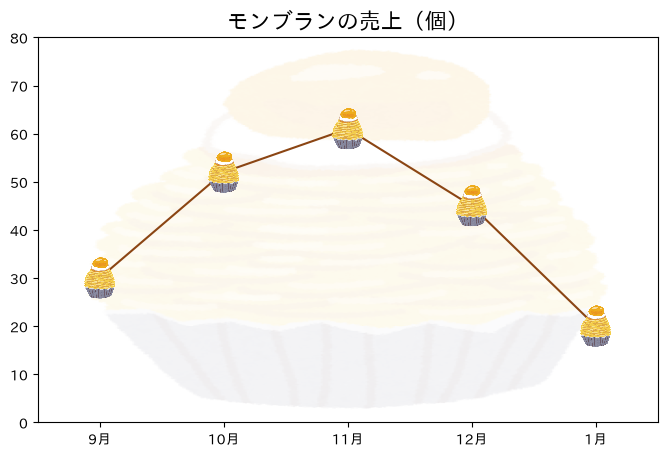

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

img = plt.imread('sweets_montblanc.png')  # [1] 画像を読む
y = [30, 52, 61, 45, 20]

plt.figure(figsize=(8, 5))
plt.plot([0, 1, 2, 3, 4], y, color='saddlebrown', zorder=1)
for i in range(len(y)):  # [2] 画像のマーカー
    box = AnnotationBbox(OffsetImage(img, zoom=0.08), (i, y[i]), frameon=False)
    plt.gca().add_artist(box)
plt.imshow(img, extent=[-0.5, 4.5, 0, 80], alpha=0.1, aspect='auto')  # [3] 背景
plt.xticks([0, 1, 2, 3, 4], ['9月', '10月', '11月', '12月', '1月'])
plt.xlim(-0.5, 4.5)
plt.ylim(0, 80)
plt.title('モンブランの売上（個）', fontsize=16)
plt.show()

### 変えてみよう（1か所変えたら、もう一度実行する）

- `zoom=0.08` → `zoom=0.15`（画像の大きさ）
- `alpha=0.1` → `alpha=0.4`（背景の濃さ）
- `y` の数を変える（例：`[30, 52, 61, 45, 20]` → `[10, 20, 70, 60, 30]`）

| 番号 | 部品 | 書き方 | 学ぶところ |
|---|---|---|---|
| [1] | 画像を読む | `img = plt.imread('画像ファイル名')` | AH-1 |
| [2] | 画像のマーカー | `for` で1つずつ `AnnotationBbox(OffsetImage(img, zoom=…), (x, y))` | AH-1 |
| [3] | 背景の画像 | `plt.imshow(img, extent=[…], alpha=0.1, aspect='auto')` | AH-3 |

In [3]:
# 上のコードを貼り付けて、値を変えてみよう

## AH-1 画像をマーカーにする

- 下のセルは**ひな形**。写して使えばよく、1行ずつ覚えなくてよい
- 変えるのは `画像ファイル名`・`x`・`y`・`zoom`（画像の大きさ）だけ
- 画像は、背景が透明な png（「いらすとや」の画像など）を使うときれいに見える

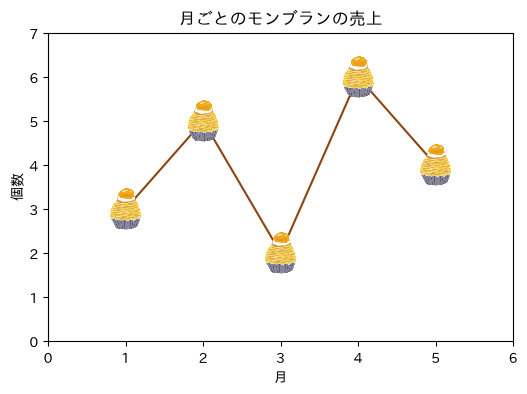

In [4]:
img = plt.imread('sweets_montblanc.png')
x = [1, 2, 3, 4, 5]
y = [3, 5, 2, 6, 4]

plt.figure(figsize=(6, 4))
plt.plot(x, y, color='saddlebrown', zorder=1)
for i in range(len(x)):
    box = AnnotationBbox(OffsetImage(img, zoom=0.08), (x[i], y[i]), frameon=False)
    plt.gca().add_artist(box)
plt.xlim(0, 6)
plt.ylim(0, 7)
plt.title('月ごとのモンブランの売上')
plt.xlabel('月')
plt.ylabel('個数')
plt.show()

- `for i in range(len(x)):` で、点の数だけ画像を置いている。for 文は第12講で学ぶ。ここでは写して使えばよい
- `(x[i], y[i])` は i 番目の点の位置
- 画像は `plt.xlim`・`plt.ylim` の範囲を自動で広げない。範囲は自分で指定する

## AH-2 記号をマーカーにする

- 第３講のハートのように、`$` で囲んだ記号をマーカーにできる
- `'$\\star$'`（星）、`'$\\clubsuit$'`（クラブ）、`'$\\bigodot$'`（二重丸）など。文字そのもの `'$A$'` も使える

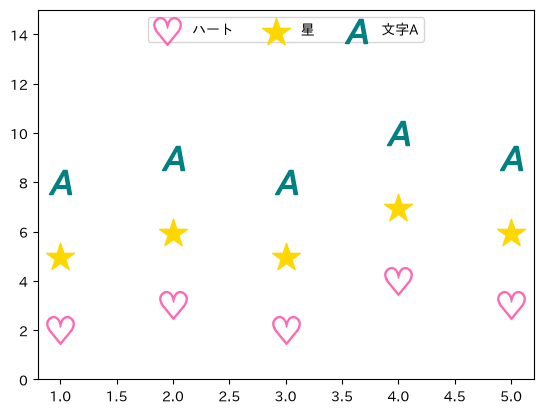

In [5]:
x = [1, 2, 3, 4, 5]
plt.scatter(x, [2, 3, 2, 4, 3], marker='$\\heartsuit$', s=400, color='hotpink', label='ハート')
plt.scatter(x, [5, 6, 5, 7, 6], marker='$\\star$', s=400, color='gold', label='星')
plt.scatter(x, [8, 9, 8, 10, 9], marker='$A$', s=300, color='teal', label='文字A')
plt.ylim(0, 15)
plt.legend(loc='upper center', ncol=3)
plt.show()

- `\\` は `\` を書くための書き方（Python の文字列の中では `\` を2つ重ねる）
- `s=` はマーカーの大きさ（散布図では `s`、折れ線では `markersize`）

## AH-3 背景に画像を敷く

- `plt.imshow(画像, extent=[x最小, x最大, y最小, y最大])` で、グラフの範囲いっぱいに画像を敷ける
- `alpha=` で薄くする。`aspect='auto'` を付けないと、画像の縦横の比に合わせてグラフがつぶれる

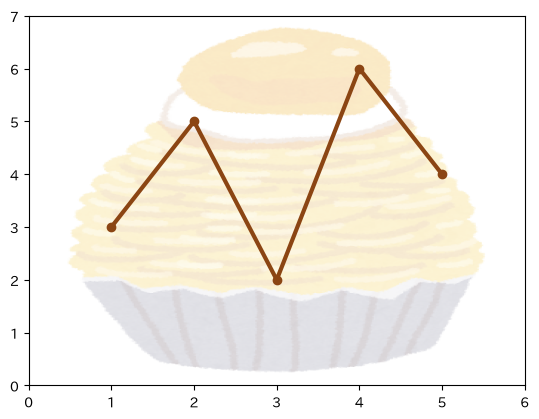

In [6]:
x = [1, 2, 3, 4, 5]
y = [3, 5, 2, 6, 4]
plt.imshow(img, extent=[0, 6, 0, 7], alpha=0.25, aspect='auto')
plt.plot(x, y, marker='o', color='saddlebrown', linewidth=3)
plt.xlim(0, 6)
plt.ylim(0, 7)
plt.show()

### 使ってみよう
- 好きな画像（png）を同じフォルダに置き、AH-1 のひな形の `'sweets_montblanc.png'` を書き換えてみよう
- データは自分で考えた数でよい（例：1週間に飲んだコーヒーの杯数）

In [7]:
# ここで試してみよう

---
# AI. 複数のグラフを並べる

## AI-1 横に並べる・縦に並べる

- 比べたいグラフは、横に並べると見比べやすい
- `plt.subplot(縦の数, 横の数, 何番目)` のあとに書いたものが、その位置のグラフに描かれる
- 番号は左上から 1, 2, 3, … と数える。最後に `plt.tight_layout()` で重なりを自動で調整する

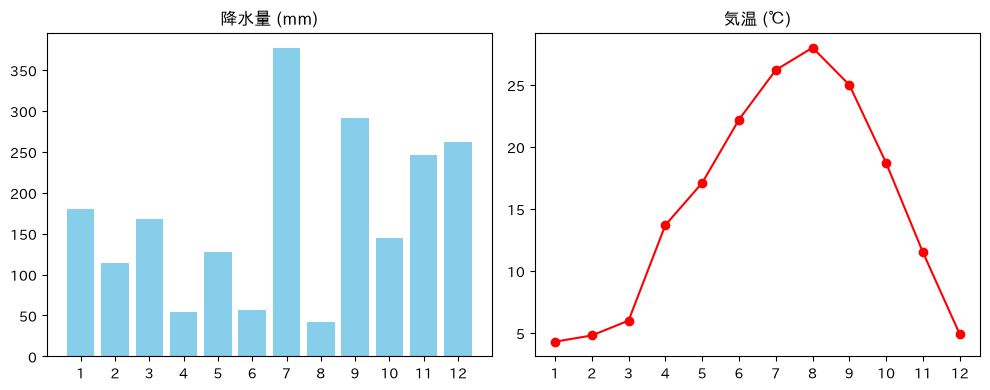

In [8]:
df_rain = pd.read_excel('dsa2026data.xlsx', sheet_name='降水量')

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.bar(df_rain['月'], df_rain['降水量'], color='skyblue')
plt.title('降水量 (mm)')
plt.xticks(range(1, 13))

plt.subplot(1, 2, 2)
plt.plot(df_rain['月'], df_rain['気温'], color='r', marker='o')
plt.title('気温 (℃)')
plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

- 第８講の複合グラフ（`plt.twinx()`）は1つのグラフに重ねる書き方、`plt.subplot` は別々のグラフを並べる書き方
- 縦に並べるときは `plt.subplot(2, 1, 1)`、`plt.subplot(2, 1, 2)`
- 第11講では、誤解を招くグラフと正しいグラフをこの書き方で並べて比べる

---
# 第２回課題

> **第２回課題（11/10 出題・11/16 締切）**：円グラフ・複合グラフ（両 y 軸）・箱ひげ図・エラーバーを使ったグラフ。ひな形の条件や色を直して作る。詳しくは授業HPを見ること。

- 第６講（円グラフ）・第７講（箱ひげ図）・第８講（複合グラフ・両 y 軸）・第９講（エラーバー）の notebook を見返しながら作る
- 次回（第11講）は総復習。課題で困ったところは、そこで質問する。解説は締切後の第12講

---
# AJ. 発展（できる人だけ）

## AJ-1 手書き風のグラフ

- `with plt.xkcd():` の下に字下げして書くと、手書き風になる
- **2行目のフォントの指定は必ず写す**。手書き風にすると文字が英語用のフォントに切り替わり、日本語が □ になるため
  - `'Comic Sans MS'`（英数字を手書き風に）→ 無い文字は `'IPAexGothic'`（japanize_matplotlib に入っている日本語フォント）で表示される
- 字下げした部分だけが手書き風になる。次のセルからは元に戻る

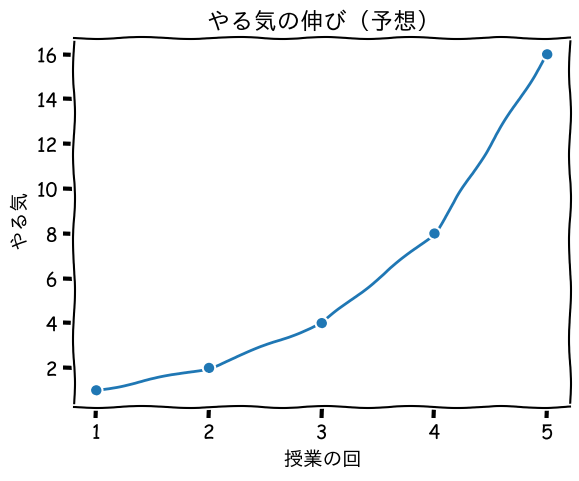

In [9]:
with plt.xkcd():
    plt.rcParams['font.family'] = ['Comic Sans MS', 'IPAexGothic']
    plt.plot([1, 2, 3, 4, 5], [1, 2, 4, 8, 16], marker='o')
    plt.title('やる気の伸び（予想）')
    plt.xlabel('授業の回')
    plt.ylabel('やる気')
    plt.show()

- Mac で `Comic Sans MS` が無いときは、英数字も `IPAexGothic` で表示される（エラーにはならない）
- `with ○○:` は、**字下げした部分の間だけ**設定を変え、終わったら元に戻す書き方。第５講 K-6 の `with plt.style.context('ggplot'):`（スタイルシート）も同じ仕組み
- 色の組み合わせ（カラーマップ）も、`with mpl.rc_context(...):` でそのグラフの間だけ変えられる（第６講 P-2 では `colors=` で指定した）

▶ **演習**（発展）：`pie_描画基礎007`（`with` でカラーマップを切り替える）

## AJ-2 手書き風フォントを入れると（紹介）

- パソコンに手書き風のフォントを入れると、文字ももっと手書きらしくできる
- 下の図は、無料で配布されているフォントを入れたパソコンで描いたもの（左上が AJ-1 の組み合わせ）

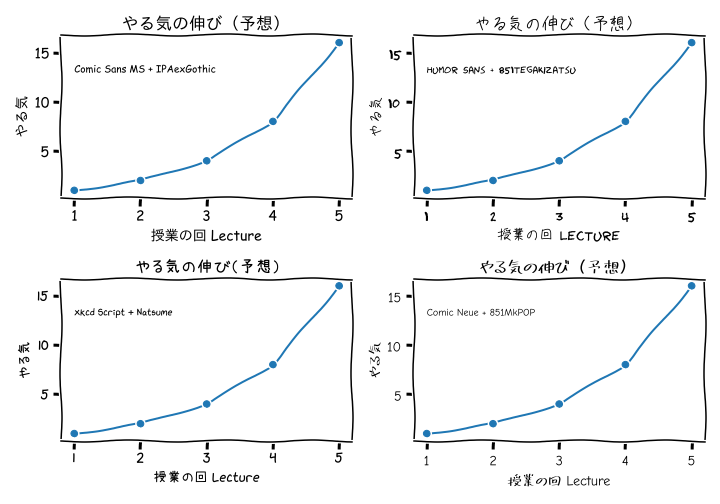

| 種類 | フォント | `font.family` に書く名前 |
|---|---|---|
| 英数字 | Humor Sans（xkcd の漫画の文字） | `'Humor Sans'` |
| 英数字 | xkcd Script | `'xkcd Script'` |
| 英数字 | Comic Neue | `'Comic Neue'` |
| 日本語 | 851手書き雑フォント | `'851tegakizatsu'` |
| 日本語 | なつめもじ | `'Natsume'` |
| 日本語 | 851マカポップ | `'851MkPOP'` |

### フォントの入れ方（例：851マカポップ）

1. [851MkPOP_101.ttf](https://pm85122.onamae.jp/851MkPOP_101.ttf) をダウンロードする（約 4.5MB）。ほかのフォントは、フォント名で検索すると配布ページが見つかる
1. ダウンロードしたファイルを開いて「インストール」（Windows は右クリック →「インストール」、Mac はダブルクリック →「Font Book」で「インストール」）
1. matplotlib が覚えているフォントの一覧（キャッシュ）を消す。下のセルで出てくるフォルダ（Windows は `C:\Users\自分の名前\.matplotlib`、Mac はホームフォルダの `.matplotlib`）を開き、`fontlist-` で始まる `.json` ファイル（例：`fontlist-v3.11.0.json`）を**全部**消す
   - `.` で始まるフォルダは隠しフォルダ。Windows はエクスプローラーの「表示」→「隠しファイル」にチェック、Mac は Finder で `Command` + `Shift` + `.`（ピリオド）
1. Kernel → Restart して、もう一度 `import` から実行する

```python
import matplotlib
print(matplotlib.get_cachedir())
```

- 書く名前はファイル名と違うことがある。入れたフォントの名前は、下のセルで一覧を出して探す


In [10]:
from matplotlib import font_manager
names = sorted({f.name for f in font_manager.fontManager.ttflist})
print(names)

['$\x82i\x82r\x83S\x83V\x83b\x83N', '$\x82i\x82r\x96¾\x92©', '%Century Oldstyle', '%CenturyOldst', '&CenturyOldst', '&Gothic720', '851MkPOP', '851tegakizatsu', '???????W3', 'Adobe Devanagari', 'Agency FB', 'Algerian', 'Arial', 'Arial Black', 'Arial Narrow', 'Arial Rounded MT Bold', 'Arphic Gansinkaisho4 Heavy JIS', 'Arphic Gothic4 Medium JIS', 'Arphic Gothic4 SuperBold JIS', 'Arphic Kaisho4 Medium JIS', 'Arphic Kaisho4JIS', 'Arphic Kanteiryu4 Heavy JIS', 'Arphic Kyokashotai4 Medium JIS', 'Arphic Kyokashotai4JIS', 'Arphic Marker-Tai4 Extra JIS', 'Arphic Match-Tai4 Bold JIS', 'Arphic Mincho4 Light JIS', 'Arphic Mincho4 Ultra JIS', 'Arphic PGansinkaisho4 Heavy JIS', 'Arphic PGothic4 Medium JIS', 'Arphic PGothic4 SuperBold JIS', 'Arphic PKaisho4 Medium JIS', 'Arphic PKaisho4JIS', 'Arphic PKanteiryu4 Heavy JIS', 'Arphic PKyokashotai4 Medium JIS', 'Arphic PKyokashotai4JIS', 'Arphic PMarker-Tai4 Extra JIS', 'Arphic PMatch-Tai4 Bold JIS', 'Arphic PMincho4 Light JIS', 'Arphic PMincho4 Ultra JIS

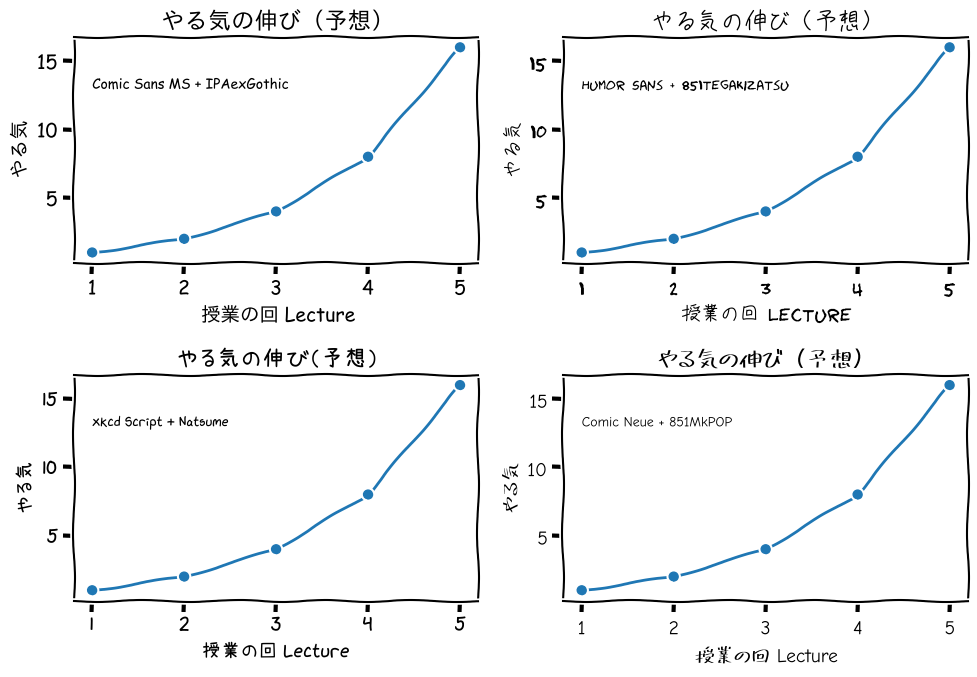

In [11]:
fonts = [
    ['Comic Sans MS', 'IPAexGothic'],
    ['Humor Sans', '851tegakizatsu', 'IPAexGothic'],
    ['xkcd Script', 'Natsume', 'IPAexGothic'],
    ['Comic Neue', '851MkPOP', 'IPAexGothic'],
]

with plt.xkcd():
    plt.figure(figsize=(10, 7))
    for i in range(len(fonts)):
        plt.rcParams['font.family'] = fonts[i]
        plt.subplot(2, 2, i + 1)
        plt.plot([1, 2, 3, 4, 5], [1, 2, 4, 8, 16], marker='o')
        plt.title('やる気の伸び（予想）')
        plt.xlabel('授業の回 Lecture')
        plt.ylabel('やる気')
        plt.text(1, 13, fonts[i][0] + ' + ' + fonts[i][1], fontsize=10)
    plt.tight_layout()
    plt.show()

- 最後の `'IPAexGothic'` は、フォントが入っていないときの予備。入っていない人が実行しても日本語は □ にならない
- フォントを入れたのに変わらないとき、`findfont: Font family '851MkPOP' not found.` と出るときは、キャッシュを消していないか、消した後に Kernel → Restart していない（上の「フォントの入れ方」の 3・4）

---
# まとめ

| やりたいこと | 書き方 |
|---|---|
| グラフを並べる | `plt.subplot(縦の数, 横の数, 何番目)`、最後に `plt.tight_layout()` |
| 画像を読む | `img = plt.imread('画像ファイル名')` |
| 画像をマーカーに | AH-1 のひな形を写し、`x`・`y`・`zoom` を変える |
| 記号をマーカーに | `marker='$\\star$'`、`marker='$A$'` |
| 背景に画像 | `plt.imshow(img, extent=[x最小, x最大, y最小, y最大], alpha=0.25, aspect='auto')` |

- 第２回課題の締切は **11/16**

次回（第11講）は**総復習**と、誤解を招かない**伝わるグラフ**のチェックリスト。